In [2]:
# ========== 12. 计算 Wigner 负性、复杂度与保真度演化 ==========

import numpy as np
import math
import qutip as qt
from scipy.optimize import minimize
import warnings
warnings.filterwarnings('ignore')

# ========= 1. 物理与计算参数设置 =========
N_dim = 50
N_DIM_OPT = 20
kappa_val = 1.0
R_IDEAL_FIXED = -0.1
plot_cases = [(0, 4), (2, 2), (1, 1)]

# 时间演化步长参数
t_max_neg = 0.5      # Wigner负性的最大演化时间
t_max_comp = 1.5     # 复杂度的最大演化时间
t_max_fide = 0.5     # 保真度的最大演化时间

tau_list_neg = np.linspace(0.0, t_max_neg, 40)
tau_list_comp = np.linspace(0.0, t_max_comp, 40)
tau_list_fide = np.linspace(0.0, t_max_fide, 40)

# ========= 2. 基础算符与目标态定义 =========
def displacement_operator(alpha, N):
    a = qt.destroy(N)
    return (alpha * a.dag() - np.conj(alpha) * a).expm()

def squeezing_operator(r, phi, N):
    a = qt.destroy(N)
    return ((r / 2) * (np.exp(-1j * phi) * a * a - np.exp(1j * phi) * a.dag() * a.dag())).expm()

def apply_gaussian_correction(state, r_corr, beta_corr, phi=0):
    N = state.shape[0]
    D = displacement_operator(beta_corr, N)
    S = squeezing_operator(r_corr, phi, N)
    if state.isket:
        rho = state * state.dag()
        return S * D * rho * D.dag() * S.dag()
    return S * D * state * D.dag() * S.dag()

def ideal_cubic_phase_state(gamma, r_ideal, N):
    a = qt.destroy(N)
    x = a + a.dag()
    S = qt.squeeze(N, r_ideal)
    O = (1j * gamma * x**3).expm()
    return (O * S * qt.fock(N, 0)).unit()

def generate_single_opa_state(g_val, alpha, m, n, N):
    g = g_val
    G = np.sqrt(1 - 1 / (g**2))
    a = qt.destroy(N)
    adag = a.dag()
    g_op = qt.Qobj(np.diag([g**(-j) for j in range(N)]), dims=[[N], [N]])
    initial_state = qt.coherent(N, alpha)
    psi_out = qt.basis(N, 0) * 0.0
    for k in range(m + 1):
        if n - m + k < 0:
            continue
        num1 = (-1)**(n - m + k)
        den1 = g**(m - k + 1)
        num2 = (G**(n - m + 2 * k)) * math.sqrt(math.factorial(n) * math.factorial(m))
        den2 = math.factorial(k) * math.factorial(n - m + k) * math.factorial(m - k)
        coef = (num1 / den1) * (num2 / den2)
        psi_out += coef * (adag**(n - m + k)) * g_op * (a**k) * initial_state
    return psi_out.unit()

def get_wigner_negativity(rho, limit=8.0, pts=150):
    xvec = np.linspace(-limit, limit, pts)
    W = qt.wigner(rho, xvec, xvec)
    dx = xvec[1] - xvec[0]
    return np.sum((np.abs(W) - W) / 2) * (dx**2)

def get_complexity_val(rho, limit=12.0, pts=300):
    if rho.isket:
        rho = rho * rho.dag()
    xvec = np.linspace(-limit, limit, pts)
    yvec = np.linspace(-limit, limit, pts)
    Q = qt.qfunc(rho, xvec, yvec)
    mask = Q > 1e-15
    dx, dy = xvec[1] - xvec[0], yvec[1] - yvec[0]
    Sw_val = -np.sum(Q[mask] * np.log(np.pi * Q[mask])) * dx * dy
    dQ_dy, dQ_dx = np.gradient(Q, dy, dx)
    I_val = 0.25 * np.sum((dQ_dx**2 + dQ_dy**2)[mask] / Q[mask]) * dx * dy
    return np.exp(Sw_val - 1.0) * I_val

# ========= 3. 寻找最优高斯修正操作 =========
def compute_fidelity_fixed_r(params, m, n, N_dim, r_ideal_fixed):
    g_val = params[0]
    gamma = params[1]
    r_corr = params[2]
    beta_corr = params[3] + 1j * params[4]
    alpha = params[5] + 1j * params[6]

    if g_val < 1.01 or g_val > 5.0:
        return 1.0
    if gamma <= 0.1 or gamma > 2.0:
        return 1.0
    if r_corr < -4 or r_corr > 4:
        return 1.0
    if abs(beta_corr) > 6:
        return 1.0
    if abs(alpha) > 6:
        return 1.0

    try:
        psi_raw = generate_single_opa_state(g_val, alpha, m, n, N_dim)
        psi_corrected = apply_gaussian_correction(psi_raw, r_corr, beta_corr)
        psi_ideal = ideal_cubic_phase_state(gamma, r_ideal_fixed, N_dim)
        if psi_corrected.isket:
            fid = qt.fidelity(psi_corrected, psi_ideal)**2
        else:
            eigvals, eigstates = psi_corrected.eigenstates()
            psi_ket = eigstates[np.argmax(eigvals)]
            fid = qt.fidelity(psi_ket, psi_ideal)**2
        return 1.0 - fid
    except Exception:
        return 1.0

def optimize_for_mn_fixed_r(m, n, N_dim, r_ideal_fixed, maxiter=800):
    initial_guesses = [
        [1.2, 0.12, 0.3, 0.0, 4.9, 0.0, -1.3],
        [1.4, 0.12, 0.3, 0.0, 4.9, 0.0, -1.3],
        [1.5, 0.15, 0.4, 0.0, 4.5, 0.0, -1.3],
        [1.6, 0.20, 0.5, 0.0, 3.5, 0.0, -1.3],
        [1.8, 0.25, 0.5, 0.0, 3.0, 0.0, -1.3],
        [1.9, 0.30, 0.5, 0.0, 2.5, 0.0, -1.3],
        [2.2, 0.30, 0.5, 0.0, 2.5, 0.0, -1.3],
        [2.4, 0.30, 0.5, 0.0, 2.5, 0.0, -1.3],
    ]
    best_result = None
    best_fidelity = -1.0

    for guess in initial_guesses:
        try:
            res = minimize(
                compute_fidelity_fixed_r,
                guess,
                args=(m, n, N_dim, r_ideal_fixed),
                method='Nelder-Mead',
                options={'maxiter': maxiter, 'xatol': 1e-5, 'fatol': 1e-5, 'disp': False}
            )
            fid = 1.0 - res.fun
            if fid > best_fidelity:
                best_fidelity = fid
                best_result = res
        except Exception:
            continue

    if best_result is None:
        raise RuntimeError(f'No optimization result for m={m}, n={n}')

    return {
        'm': m,
        'n': n,
        'g_val': best_result.x[0],
        'gamma': best_result.x[1],
        'r_corr': best_result.x[2],
        'beta_corr': best_result.x[3] + 1j * best_result.x[4],
        'alpha': best_result.x[5] + 1j * best_result.x[6],
        'r_ideal': r_ideal_fixed,
        'fidelity': best_fidelity
    }

# ========= 4. 主循环：耗散演化与指标计算 =========
print('>>> 开始计算态的时间演化与相关指标...')
H = qt.Qobj(np.zeros((N_dim, N_dim)))
a_loss = qt.destroy(N_dim)
c_ops_neg = [np.sqrt(kappa_val) * a_loss]       # Wigner负性耗散算符
c_ops_fide = [np.sqrt(kappa_val) * a_loss]      # 保真度耗散算符
has_external_complexity_data = all(
    name in globals() for name in ['init_rhos', 'target_kets', 'H_zero', 'a_op']
)

merged_results = {}
for (m, n) in plot_cases:
    print(f'--> 正在处理 m={m}, n={n} ...')
    opt = optimize_for_mn_fixed_r(m, n, N_DIM_OPT, R_IDEAL_FIXED)
    print(f"    最佳初态保真度: {opt['fidelity']:.4f}")

    psi_raw = generate_single_opa_state(opt['g_val'], opt['alpha'], m, n, N_dim)
    psi_init = apply_gaussian_correction(psi_raw, opt['r_corr'], opt['beta_corr'])
    psi_ideal = ideal_cubic_phase_state(opt['gamma'], R_IDEAL_FIXED, N_dim)

    # 计算 Wigner 负性演化
    me_neg = qt.mesolve(H, psi_init, tau_list_neg, c_ops_neg, [])
    neg_array = [get_wigner_negativity(state, limit=8.0, pts=150) for state in me_neg.states]

    # 计算 保真度 演化
    me_fide = qt.mesolve(H, psi_init, tau_list_fide, c_ops_fide, [])
    fide_array = [qt.fidelity(state, psi_ideal)**2 for state in me_fide.states]

    # 计算 复杂度 演化
    if has_external_complexity_data and (m, n) in init_rhos and (m, n) in target_kets:
        rho_comp_init = init_rhos[(m, n)]
        psi_comp_ideal = target_kets[(m, n)]
        H_comp = H_zero
        a_comp = a_op
    else:
        rho_comp_init = psi_init
        psi_comp_ideal = psi_ideal
        H_comp = H
        a_comp = a_loss

    c_ops_comp = [np.sqrt(2 * kappa_val) * a_comp]  # 注意复杂度的耗散系数设定
    me_comp = qt.mesolve(H_comp, rho_comp_init, tau_list_comp / kappa_val, c_ops_comp, [])
    comp_array = [get_complexity_val(state, limit=12.0, pts=300) for state in me_comp.states]

    merged_results[(m, n)] = {
        'neg': neg_array,
        'fide_neg': fide_array,
        'comp': comp_array,
        'fide_comp': fide_array,
    }
print('>>> 计算完成！')
# ============================================================
# 提取并打印每种情况的 10 个均匀分布的 Photon Loss 数据点
# ============================================================
print("\n" + "="*60)
print("开始提取 10 个均匀分布的 Photon Loss 数据点")
print("="*60)

# 从总长度 40 中均匀提取 10 个索引点
idx_neg = np.linspace(0, len(tau_list_neg) - 1, 10, dtype=int)
idx_comp = np.linspace(0, len(tau_list_comp) - 1, 10, dtype=int)
idx_fide = np.linspace(0, len(tau_list_fide) - 1, 10, dtype=int)

for (m, n) in plot_cases:
    print(f"\n[{'='*15} Case: m={m}, n={n} {'='*15}]")
    data = merged_results[(m, n)]
    
    # ---- 1. Wigner 负性 ----
    print("\n1. Wigner 负性 (Negativity):")
    print(f"  {'Photon Loss (kappa*tau)':>25} | {'Negativity':>15}")
    print("  " + "-"*43)
    for i in idx_neg:
        print(f"  {tau_list_neg[i]:25.4f} | {data['neg'][i]:15.4f}")
        
    # ---- 2. 复杂度 ----
    print("\n2. 复杂度 (Complexity):")
    print(f"  {'Photon Loss (kappa*t)':>25} | {'Complexity':>15}")
    print("  " + "-"*43)
    for i in idx_comp:
        print(f"  {tau_list_comp[i]:25.4f} | {data['comp'][i]:15.4f}")
        
    # ---- 3. 保真度 ----
    print("\n3. 保真度 (Fidelity):")
    print(f"  {'Photon Loss (kappa*t)':>25} | {'Fidelity':>15}")
    print("  " + "-"*43)
    for i in idx_fide:
        print(f"  {tau_list_fide[i]:25.4f} | {data['fide_neg'][i]:15.4f}")

print("\n>>> 数据打印完毕！")

>>> 开始计算态的时间演化与相关指标...
--> 正在处理 m=0, n=4 ...
    最佳初态保真度: 0.9948
--> 正在处理 m=2, n=2 ...
    最佳初态保真度: 0.9875
--> 正在处理 m=1, n=1 ...
    最佳初态保真度: 0.9776
>>> 计算完成！

开始提取 10 个均匀分布的 Photon Loss 数据点

[=============== Case: m=0, n=4 ===============]

1. Wigner 负性 (Negativity):
    Photon Loss (kappa*tau) |      Negativity
  -------------------------------------------
                     0.0000 |          0.0728
                     0.0513 |          0.0523
                     0.1026 |          0.0384
                     0.1667 |          0.0263
                     0.2179 |          0.0194
                     0.2692 |          0.0141
                     0.3333 |          0.0093
                     0.3846 |          0.0063
                     0.4359 |          0.0041
                     0.5000 |          0.0021

2. 复杂度 (Complexity):
      Photon Loss (kappa*t) |      Complexity
  -------------------------------------------
                     0.0000 |          1.1296
                   

>>> 开始生成图表...


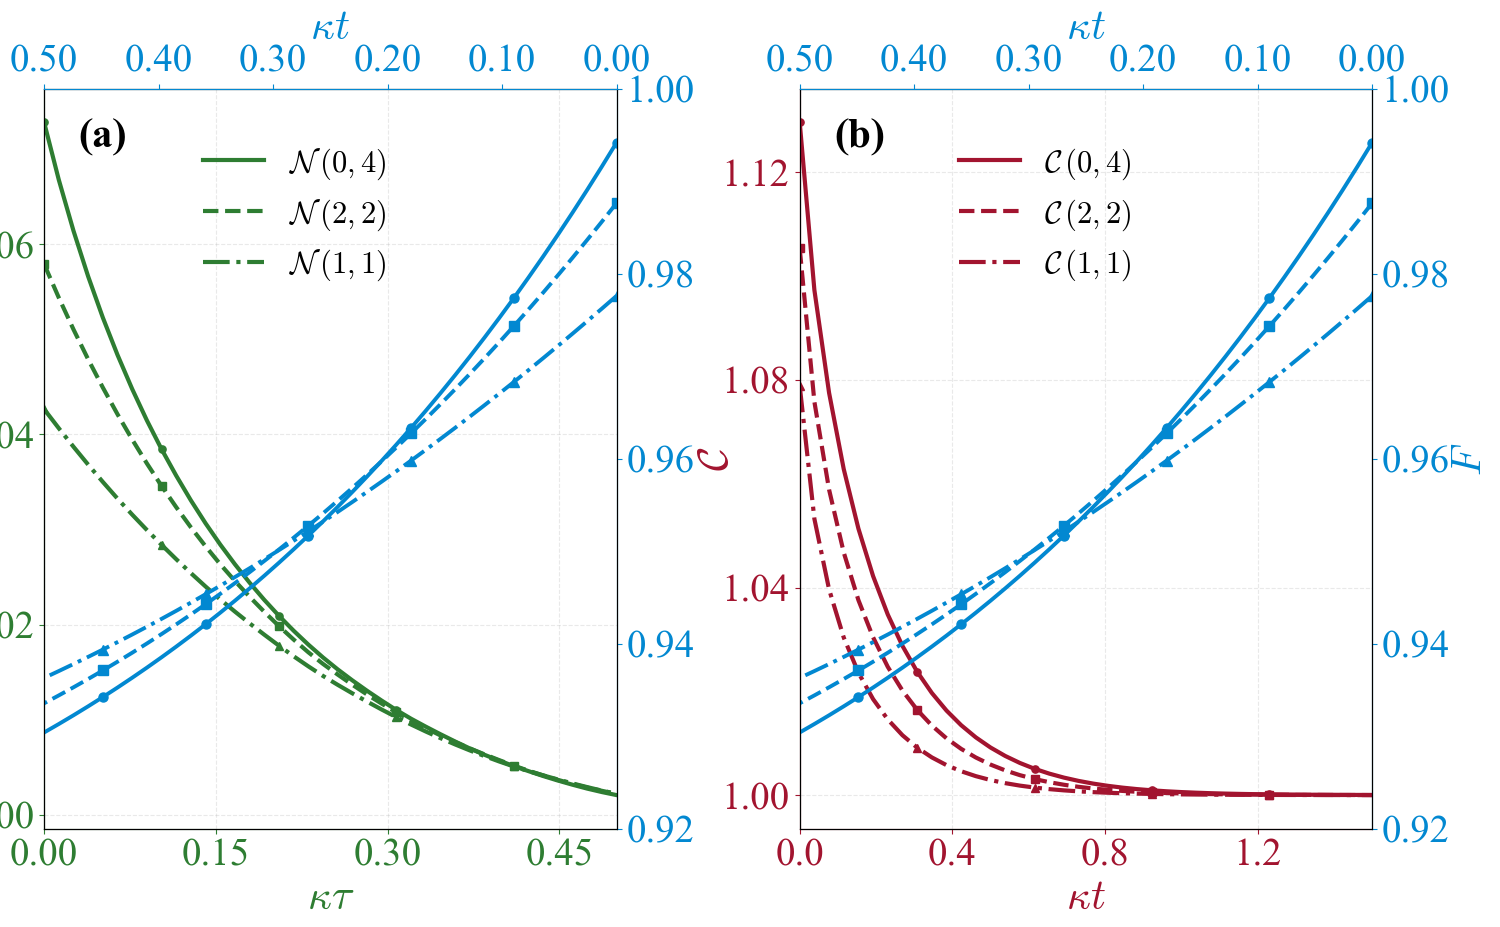

>>> 图表绘制保存完毕！


In [21]:
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.ticker import MaxNLocator, FormatStrFormatter

# ========= 5. 画图样式与字体参数设置 =========
plt.style.use('seaborn-v0_8-muted')

BASE_FONT_SIZE = 19       # 基础字号
AXIS_LABEL_SIZE = 30      # 坐标轴标签 (F, C, kappa*t)
TICK_LABEL_SIZE = 28      # 坐标轴刻度字体大小
LEGEND_FONT_SIZE = 22     # 图例字号
PANEL_LABEL_SIZE = 30     # 子图标记 (a) (b) 字号
TOP_LABEL_SIZE = 30       # 顶部 x 轴标签字号

# --- 图例位置调节 ---
NEG_LEGEND_LOC = 'upper left'
NEG_LEGEND_ANCHOR = (0.23, 0.96)   # Wigner图的图例锚点
COMP_LEGEND_LOC = 'upper left'
COMP_LEGEND_ANCHOR = (0.23, 0.96)  # 复杂度图的图例锚点

mpl.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman'],
    'mathtext.fontset': 'cm',
    'font.size': BASE_FONT_SIZE,
    'axes.labelsize': AXIS_LABEL_SIZE,
    'xtick.labelsize': TICK_LABEL_SIZE,
    'ytick.labelsize': TICK_LABEL_SIZE,
    'legend.fontsize': LEGEND_FONT_SIZE,
    'text.usetex': False
})

# X轴刻度预设
neg_bottom_ticks = [0.00, 0.15, 0.30, 0.45]
comp_bottom_ticks = [0.0, 0.4, 0.8, 1.2]
top_fide_ticks = [0.50,0.40,0.30,0.20, 0.10, 0.00]

# ========= 6. 开始绘制图表 =========
print('>>> 开始生成图表...')
FIG_SIZE = (16, 10)
PANEL_BOX_ASPECT = 2.0  # 子图高宽比
MIDDLE_C_LABEL_X = -0.11
OUTER_F_LABEL_X = 1.14

fig, (ax_neg, ax_comp) = plt.subplots(1, 2, figsize=FIG_SIZE)
for ax in (ax_neg, ax_comp):
    ax.set_box_aspect(PANEL_BOX_ASPECT)

color_neg = '#2E7D32'
color_comp = '#A2142F'
color_fide = '#0288D1'
styles = ['-', '--', '-.', ':']
markers = ['o', 's', '^', 'D']

SHOW_PRIMARY_MARKERS = True
PRIMARY_MARKER_SIZE = 5.2
PRIMARY_MARK_EVERY = 8

# ==============================================================
# ---- (a) Wigner 负性 + 保真度 ----
# ==============================================================
ax_fide_neg = ax_neg.twinx()
ax_top_neg = ax_fide_neg.twiny()

ax_neg.set_xlim(0, t_max_neg)
ax_neg.set_xticks(neg_bottom_ticks)
ax_neg.xaxis.set_major_formatter(FormatStrFormatter('%.2f'))
ax_neg.yaxis.set_major_locator(MaxNLocator(nbins=4))
ax_neg.set_xlabel(r'$\kappa \tau$', color=color_neg)
ax_neg.set_ylabel(r'$\mathcal{N}$', color=color_neg, labelpad=8)
ax_neg.tick_params(axis='x', colors=color_neg)
ax_neg.tick_params(axis='y', colors=color_neg)
ax_neg.spines['bottom'].set_color(color_neg)
ax_neg.spines['left'].set_color(color_neg)

ax_fide_neg.set_ylim(0.95, 1.00)
ax_fide_neg.set_yticks([0.92,0.94, 0.96, 0.98, 1.00])
ax_fide_neg.tick_params(axis='y', colors=color_fide)
ax_fide_neg.spines['right'].set_color(color_fide)

ax_top_neg.set_xlim(t_max_fide, 0.0)
ax_top_neg.set_xticks(top_fide_ticks)
ax_top_neg.xaxis.set_major_formatter(FormatStrFormatter('%.2f'))
ax_top_neg.set_xlabel(r'$\kappa t$', color=color_fide, fontsize=TOP_LABEL_SIZE)
ax_top_neg.tick_params(axis='x', colors=color_fide)
ax_top_neg.spines['top'].set_color(color_fide)

lines_neg = []
for i, (m, n) in enumerate(plot_cases):
    res_data = merged_results[(m, n)]
    ln, = ax_neg.plot(tau_list_neg, res_data['neg'], color=color_neg,
                      ls=styles[i], lw=3.0,
                      marker=markers[i] if SHOW_PRIMARY_MARKERS else None,
                      ms=PRIMARY_MARKER_SIZE, markevery=PRIMARY_MARK_EVERY,
                      label=fr'$\mathcal{{N}}\,({m},{n})$')
    ax_top_neg.plot(tau_list_fide, res_data['fide_neg'], color=color_fide,
                    ls=styles[i], marker=markers[i], ms=6.5, markevery=7, lw=2.8,
                    label='_nolegend_')
    lines_neg.append(ln)

ax_neg.grid(True, ls='--', alpha=0.28)
leg_neg = ax_neg.legend(lines_neg, [line.get_label() for line in lines_neg],
                        loc=NEG_LEGEND_LOC, bbox_to_anchor=NEG_LEGEND_ANCHOR,
                        frameon=False, fontsize=LEGEND_FONT_SIZE)
for handle in (getattr(leg_neg, 'legend_handles', None) or leg_neg.legendHandles):
    handle.set_marker('')
ax_neg.text(0.06, 0.96, '(a)', transform=ax_neg.transAxes,
            fontsize=PANEL_LABEL_SIZE, fontweight='bold', va='top', ha='left')

# ==============================================================
# ---- (b) 复杂度 + 保真度 ----
# ==============================================================
ax_fide_comp = ax_comp.twinx()
ax_top_comp = ax_fide_comp.twiny()

ax_comp.set_xlim(0, t_max_comp)
ax_comp.set_xticks(comp_bottom_ticks)
ax_comp.xaxis.set_major_formatter(FormatStrFormatter('%.1f'))
ax_comp.yaxis.set_major_locator(MaxNLocator(nbins=4))
ax_comp.set_xlabel(r'$\kappa t$', color=color_comp)
ax_comp.set_ylabel(r'$\mathcal{C}$', color=color_comp, labelpad=8)
ax_comp.yaxis.set_label_coords(MIDDLE_C_LABEL_X, 0.50)
ax_comp.tick_params(axis='x', colors=color_comp)
ax_comp.tick_params(axis='y', colors=color_comp)
ax_comp.spines['bottom'].set_color(color_comp)
ax_comp.spines['left'].set_color(color_comp)

ax_fide_comp.set_ylim(0.95, 1.00)
ax_fide_comp.set_yticks([0.92,0.94, 0.96, 0.98, 1.00])
ax_fide_comp.set_ylabel(r'$F$', color=color_fide, labelpad=8)
ax_fide_comp.yaxis.set_label_coords(OUTER_F_LABEL_X, 0.50)
ax_fide_comp.tick_params(axis='y', colors=color_fide)
ax_fide_comp.spines['right'].set_color(color_fide)

ax_top_comp.set_xlim(t_max_fide, 0.0)
ax_top_comp.set_xticks(top_fide_ticks)
ax_top_comp.xaxis.set_major_formatter(FormatStrFormatter('%.2f'))
ax_top_comp.set_xlabel(r'$\kappa t$', color=color_fide, fontsize=TOP_LABEL_SIZE)
ax_top_comp.tick_params(axis='x', colors=color_fide)
ax_top_comp.spines['top'].set_color(color_fide)

lines_comp = []
for i, (m, n) in enumerate(plot_cases):
    res_data = merged_results[(m, n)]
    lc, = ax_comp.plot(tau_list_comp, res_data['comp'], color=color_comp,
                       ls=styles[i], lw=3.0,
                       marker=markers[i] if SHOW_PRIMARY_MARKERS else None,
                       ms=PRIMARY_MARKER_SIZE, markevery=PRIMARY_MARK_EVERY,
                       label=fr'$\mathcal{{C}}\,({m},{n})$')
    ax_top_comp.plot(tau_list_fide, res_data['fide_comp'], color=color_fide,
                     ls=styles[i], marker=markers[i], ms=6.5, markevery=7, lw=2.8,
                     label='_nolegend_')
    lines_comp.append(lc)

ax_comp.grid(True, ls='--', alpha=0.28)
leg_comp = ax_comp.legend(lines_comp, [line.get_label() for line in lines_comp],
                          loc=COMP_LEGEND_LOC, bbox_to_anchor=COMP_LEGEND_ANCHOR,
                          frameon=False, fontsize=LEGEND_FONT_SIZE)
for handle in (getattr(leg_comp, 'legend_handles', None) or leg_comp.legendHandles):
    handle.set_marker('')
ax_comp.text(0.06, 0.96, '(b)', transform=ax_comp.transAxes,
             fontsize=PANEL_LABEL_SIZE, fontweight='bold', va='top', ha='left')

fig.subplots_adjust(left=0.08, right=0.91, bottom=0.13, top=0.87, wspace=0.32)

plt.savefig('merged_negativity_complexity_fidelity_layout.pdf', dpi=300, bbox_inches='tight')
plt.savefig('merged_negativity_complexity_fidelity_layout.png', dpi=300, bbox_inches='tight')
plt.show()
print('>>> 图表绘制保存完毕！')

>>> 开始生成图表...


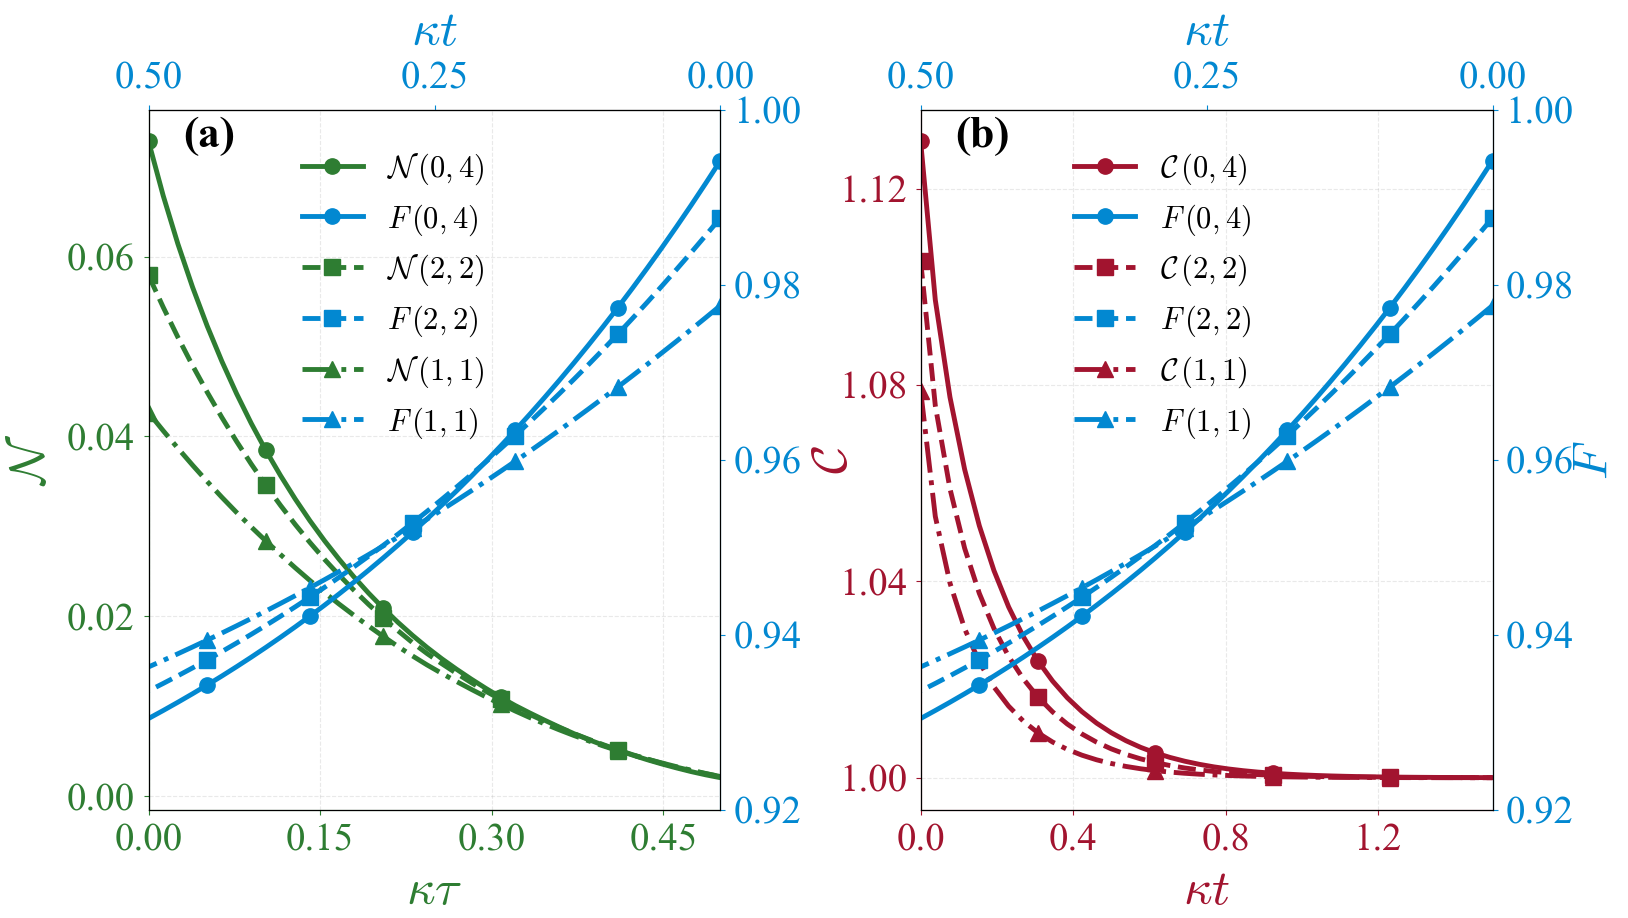

>>> 图表绘制保存完毕！


In [3]:
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.ticker import MaxNLocator, FormatStrFormatter

# ========= 5. 画图样式与字体参数设置 (套用标准双栏格式) =========
plt.style.use('seaborn-v0_8-muted')

BASE_FONT_SIZE = 19       # 基础字号
AXIS_LABEL_SIZE = 36      # 坐标轴标签 (F, C, kappa*t) - 已统一
TICK_LABEL_SIZE = 28      # 坐标轴刻度字体大小 - 已统一
LEGEND_FONT_SIZE = 22     # 图例字号 - 已统一
PANEL_LABEL_SIZE = 32     # 子图标记 (a) (b) 字号 - 已统一
TOP_LABEL_SIZE = 36       # 顶部 x 轴标签字号 - 与 AXIS_LABEL_SIZE 统一

LINE_WIDTH = 3.5          # 统一线宽
MARKER_SIZE = 11          # 统一数据点大小

# --- 图例位置调节 (左上角，已避开角标) ---
LEGEND_POS_A = (0.22, 0.98)  # Wigner图的图例锚点 (X=0.22 避开左侧的(a))
LEGEND_POS_B = (0.22, 0.98)  # 复杂度图的图例锚点 (X=0.22 避开左侧的(b))

mpl.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman'],
    'mathtext.fontset': 'cm',
    'font.size': BASE_FONT_SIZE,
    'axes.labelsize': AXIS_LABEL_SIZE,
    'xtick.labelsize': TICK_LABEL_SIZE,
    'ytick.labelsize': TICK_LABEL_SIZE,
    'legend.fontsize': LEGEND_FONT_SIZE,
    'text.usetex': False
})

# X轴刻度预设
neg_bottom_ticks = [0.00, 0.15, 0.30, 0.45]
comp_bottom_ticks = [0.0, 0.4, 0.8, 1.2]
top_fide_ticks = [0.50, 0.25, 0.00]

# ========= 6. 开始绘制图表 =========
print('>>> 开始生成图表...')
FIG_SIZE = (16, 10)       # 统一为 16x10
PANEL_BOX_ASPECT = 1.2    # 子图高宽比
MIDDLE_C_LABEL_X = -0.11
OUTER_F_LABEL_X = 1.14

fig, (ax_neg, ax_comp) = plt.subplots(1, 2, figsize=FIG_SIZE)
for ax in (ax_neg, ax_comp):
    ax.set_box_aspect(PANEL_BOX_ASPECT)

color_neg = '#2E7D32'
color_comp = '#A2142F'
color_fide = '#0288D1'
styles = ['-', '--', '-.', ':']
markers = ['o', 's', '^', 'D']

SHOW_PRIMARY_MARKERS = True
PRIMARY_MARK_EVERY = 8
FIDE_MARK_EVERY = 7       # 保真度的 Marker 间隔

# ==============================================================
# ---- (a) Wigner 负性 + 保真度 ----
# ==============================================================
ax_fide_neg = ax_neg.twinx()
ax_top_neg = ax_fide_neg.twiny()

ax_neg.set_xlim(0, t_max_neg)
ax_neg.set_xticks(neg_bottom_ticks)
ax_neg.xaxis.set_major_formatter(FormatStrFormatter('%.2f'))
ax_neg.yaxis.set_major_locator(MaxNLocator(nbins=4))
ax_neg.set_xlabel(r'$\kappa \tau$', color=color_neg, labelpad=8)
ax_neg.set_ylabel(r'$\mathcal{N}$', color=color_neg, labelpad=8)
ax_neg.tick_params(axis='x', colors=color_neg, pad=6)
ax_neg.tick_params(axis='y', colors=color_neg, pad=6)
ax_neg.spines['bottom'].set_color(color_neg)
ax_neg.spines['left'].set_color(color_neg)

ax_fide_neg.set_ylim(0.95, 1.00)
ax_fide_neg.set_yticks([0.92, 0.94, 0.96, 0.98, 1.00])
ax_fide_neg.tick_params(axis='y', colors=color_fide, pad=6)
ax_fide_neg.spines['right'].set_color(color_fide)

ax_top_neg.set_xlim(t_max_fide, 0.0)
ax_top_neg.set_xticks(top_fide_ticks)
ax_top_neg.xaxis.set_major_formatter(FormatStrFormatter('%.2f'))
ax_top_neg.set_xlabel(r'$\kappa t$', color=color_fide, fontsize=TOP_LABEL_SIZE, labelpad=12)
ax_top_neg.tick_params(axis='x', colors=color_fide, pad=6)
ax_top_neg.spines['top'].set_color('black')

lines_a = []
for i, (m, n) in enumerate(plot_cases):
    res_data = merged_results[(m, n)]
    
    # 绘制负性曲线
    ln, = ax_neg.plot(tau_list_neg, res_data['neg'], color=color_neg,
                      ls=styles[i], lw=LINE_WIDTH,
                      marker=markers[i] if SHOW_PRIMARY_MARKERS else None,
                      ms=MARKER_SIZE, markevery=PRIMARY_MARK_EVERY,
                      label=fr'$\mathcal{{N}}\,({m},{n})$')
                      
    # 绘制保真度曲线，并加上标签 (去除了 _nolegend_)
    lf, = ax_top_neg.plot(tau_list_fide, res_data['fide_neg'], color=color_fide,
                          ls=styles[i], marker=markers[i], ms=MARKER_SIZE, 
                          markevery=FIDE_MARK_EVERY, lw=LINE_WIDTH,
                          label=fr'$F\,({m},{n})$')
                          
    # 同时将两条线加入图例列表
    lines_a.extend([ln, lf])

ax_neg.grid(True, ls='--', alpha=0.28)

# 【已修改】：loc 设为 upper left
ax_neg.legend(lines_a, [l.get_label() for l in lines_a],
              loc='upper left', bbox_to_anchor=LEGEND_POS_A,
              frameon=False, fontsize=LEGEND_FONT_SIZE, ncol=1)

ax_neg.text(0.06, 0.99, '(a)', transform=ax_neg.transAxes,
            fontsize=PANEL_LABEL_SIZE, fontweight='bold', va='top', ha='left')

# ==============================================================
# ---- (b) 复杂度 + 保真度 ----
# ==============================================================
ax_fide_comp = ax_comp.twinx()
ax_top_comp = ax_fide_comp.twiny()

ax_comp.set_xlim(0, t_max_comp)
ax_comp.set_xticks(comp_bottom_ticks)
ax_comp.xaxis.set_major_formatter(FormatStrFormatter('%.1f'))
ax_comp.yaxis.set_major_locator(MaxNLocator(nbins=4))
ax_comp.set_xlabel(r'$\kappa t$', color=color_comp, labelpad=8)
ax_comp.set_ylabel(r'$\mathcal{C}$', color=color_comp, labelpad=8)
ax_comp.yaxis.set_label_coords(MIDDLE_C_LABEL_X, 0.50)
ax_comp.tick_params(axis='x', colors=color_comp, pad=6)
ax_comp.tick_params(axis='y', colors=color_comp, pad=6)
ax_comp.spines['bottom'].set_color(color_comp)
ax_comp.spines['left'].set_color(color_comp)

ax_fide_comp.set_ylim(0.95, 1.00)
ax_fide_comp.set_yticks([0.92, 0.94, 0.96, 0.98, 1.00])
ax_fide_comp.set_ylabel(r'$F$', color=color_fide, labelpad=8)
ax_fide_comp.yaxis.set_label_coords(OUTER_F_LABEL_X, 0.50)
ax_fide_comp.tick_params(axis='y', colors=color_fide, pad=6)
ax_fide_comp.spines['right'].set_color(color_fide)

ax_top_comp.set_xlim(t_max_fide, 0.0)
ax_top_comp.set_xticks(top_fide_ticks)
ax_top_comp.xaxis.set_major_formatter(FormatStrFormatter('%.2f'))
ax_top_comp.set_xlabel(r'$\kappa t$', color=color_fide, fontsize=TOP_LABEL_SIZE, labelpad=12)
ax_top_comp.tick_params(axis='x', colors=color_fide, pad=6)
ax_top_comp.spines['top'].set_color('black')

lines_b = []
for i, (m, n) in enumerate(plot_cases):
    res_data = merged_results[(m, n)]
    
    # 绘制复杂度曲线
    lc, = ax_comp.plot(tau_list_comp, res_data['comp'], color=color_comp,
                       ls=styles[i], lw=LINE_WIDTH,
                       marker=markers[i] if SHOW_PRIMARY_MARKERS else None,
                       ms=MARKER_SIZE, markevery=PRIMARY_MARK_EVERY,
                       label=fr'$\mathcal{{C}}\,({m},{n})$')
                       
    # 绘制保真度曲线，并加上标签 (去除了 _nolegend_)
    lf, = ax_top_comp.plot(tau_list_fide, res_data['fide_comp'], color=color_fide,
                           ls=styles[i], marker=markers[i], ms=MARKER_SIZE, 
                           markevery=FIDE_MARK_EVERY, lw=LINE_WIDTH,
                           label=fr'$F\,({m},{n})$')
                           
    # 同时将两条线加入图例列表
    lines_b.extend([lc, lf])

ax_comp.grid(True, ls='--', alpha=0.28)

# 【已修改】：loc 设为 upper left
ax_comp.legend(lines_b, [l.get_label() for l in lines_b],
               loc='upper left', bbox_to_anchor=LEGEND_POS_B,
               frameon=False, fontsize=LEGEND_FONT_SIZE, ncol=1)

ax_comp.text(0.06, 0.99, '(b)', transform=ax_comp.transAxes,
             fontsize=PANEL_LABEL_SIZE, fontweight='bold', va='top', ha='left')

# 统一调整间距 wspace=0.32
fig.subplots_adjust(left=0.08, right=0.92, bottom=0.15, top=0.85, wspace=0.35)

plt.savefig('merged_negativity_complexity_fidelity_layout.pdf', dpi=400, bbox_inches='tight')
plt.savefig('merged_negativity_complexity_fidelity_layout.png', dpi=400, bbox_inches='tight')
plt.show()
print('>>> 图表绘制保存完毕！')